# Лабораторная работа №1. Повышение разрешения изображений

SRGAN восстанавливает изображение 256×256 из изображения 64×64.
[Задание](https://github.com/JustHawker/AIT_Course_SamU_2026/blob/autumn-2026/Лабораторные/ЛР1.md) ·
[Статья SRGAN](https://arxiv.org/abs/1609.04802).

## 1. Подготовка библиотек и параметров эксперимента

In [1]:
from pathlib import Path
import json
import random
import urllib.request
import zipfile

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm import tqdm
import torch
from torch import nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import vgg19, VGG19_Weights

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

SCALE = 4
HR_SIZE = 256
LR_SIZE = HR_SIZE // SCALE
BATCH_SIZE = 4
PRETRAIN_EPOCHS = 20
GAN_EPOCHS = 20
LEARNING_RATE = 1e-4
ADV_WEIGHT = 1e-3

DATA_DIR = Path('datasets/coco')
IMAGE_DIR = DATA_DIR / 'val2017'
RESULTS_DIR = Path('runs/srgan_coco_simple')
DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
torch.hub.set_dir(str(Path('models/torch_hub').resolve()))
print('Устройство:', DEVICE)

Устройство: cuda


## 2. Формирование обучающих пар из COCO
Используем [COCO val2017](https://cocodataset.org/#download): 5000 фотографий.
После исключения маленьких снимков получаем 3966/495/497 изображений для train/val/test.

HR — фрагмент 256×256, LR — его уменьшение в 4 раза через bicubic. Для train
используем случайный фрагмент и отражение, для val/test — центральный фрагмент.
Обе картинки представлены RGB-тензорами в [0, 1].

In [2]:
# При повторном запуске используем уже скачанные изображения и готовое разбиение.
if not IMAGE_DIR.exists():
    archive_path = DATA_DIR / 'val2017.zip'
    urllib.request.urlretrieve(
        'https://s3.amazonaws.com/images.cocodataset.org/zips/val2017.zip', archive_path)
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(DATA_DIR)

split_path = DATA_DIR / 'sr_x4_split.json'
if not split_path.exists():
    names = []
    for path in sorted(IMAGE_DIR.glob('*.jpg')):
        with Image.open(path) as image:
            if min(image.size) >= HR_SIZE:
                names.append(path.name)
    random.Random(SEED).shuffle(names)
    n_train, n_val = int(len(names) * 0.8), int(len(names) * 0.1)
    splits = dict(train=names[:n_train], val=names[n_train:n_train+n_val],
                  test=names[n_train+n_val:])
    split_path.write_text(json.dumps({'splits': splits}, indent=2), encoding='utf-8')

splits = json.loads(split_path.read_text(encoding='utf-8'))['splits']
print({name: len(files) for name, files in splits.items()})

{'train': 3966, 'val': 495, 'test': 497}


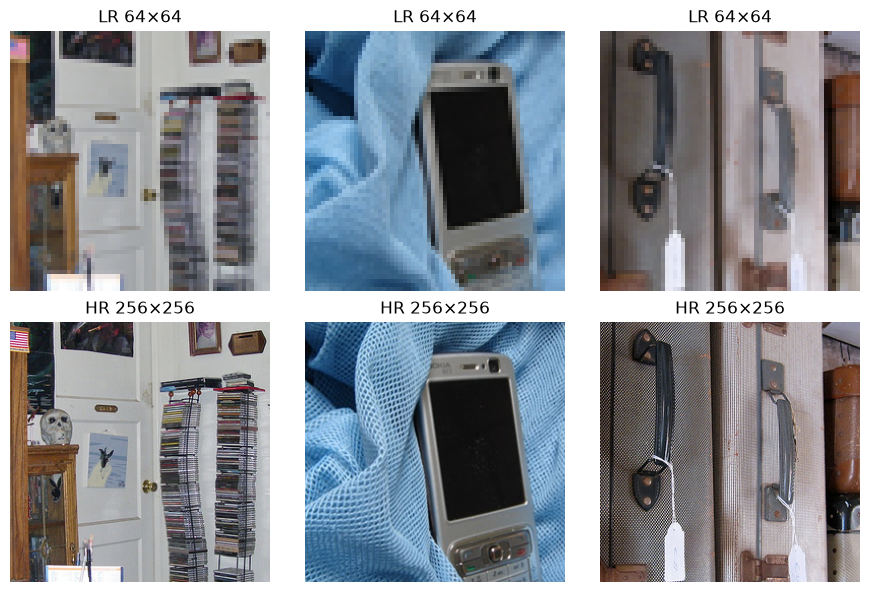

In [3]:
class CocoDataset(Dataset):
    def __init__(self, filenames, train=False):
        self.filenames = filenames
        self.crop = transforms.CenterCrop(HR_SIZE)
        if train:
            self.crop = transforms.Compose([
                transforms.RandomCrop(HR_SIZE), transforms.RandomHorizontalFlip()])
        self.to_tensor = transforms.ToTensor()

    def __len__(self):
        return len(self.filenames)

    def __getitem__(self, index):
        with Image.open(IMAGE_DIR / self.filenames[index]) as image:
            hr = self.crop(ImageOps.exif_transpose(image).convert('RGB'))
        lr = hr.resize((LR_SIZE, LR_SIZE), Image.Resampling.BICUBIC)
        return self.to_tensor(lr), self.to_tensor(hr)


train_dataset = CocoDataset(splits['train'], train=True)
val_dataset = CocoDataset(splits['val'])
test_dataset = CocoDataset(splits['test'])
# num_workers=0 подходит для notebook на Windows.
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, num_workers=0)

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for column in range(3):
    lr, hr = val_dataset[column]
    for row, image, title in [(0, lr, 'LR 64×64'), (1, hr, 'HR 256×256')]:
        axes[row, column].imshow(image.permute(1, 2, 0))
        axes[row, column].set_title(title)
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()

## 3. Построение нейросетевых компонентов SRGAN
Генератор: 16 residual-блоков и два PixelShuffle ×2. Дискриминатор: восемь
свёрток и два полносвязных слоя. Его выход — логит для `BCEWithLogitsLoss`.
VGG19 даёт признаки relu5_4 для контентной ошибки; её веса не обучаются.

Архитектура совместима с ранее сохранёнными весами. Адаптации относительно статьи:
RGB в [0, 1], AdaptiveAvgPool 6×6 в D для наших патчей 256×256 и обычное среднее
MSE признаков ImageNet-нормализованной torchvision VGG19 без множителя 1/12.75.

In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, channels=64):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
            nn.PReLU(channels),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.BatchNorm2d(channels),
        )

    def forward(self, x):
        return x + self.body(x)


class Generator(nn.Module):
    def __init__(self, num_blocks=16):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, 64, 9, padding=4), nn.PReLU(64))
        self.residuals = nn.Sequential(*[ResidualBlock() for _ in range(num_blocks)])
        self.trunk = nn.Sequential(nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64))
        self.upsample = nn.Sequential(
            nn.Conv2d(64, 256, 3, padding=1), nn.PixelShuffle(2), nn.PReLU(64),
            nn.Conv2d(64, 256, 3, padding=1), nn.PixelShuffle(2), nn.PReLU(64),
        )
        self.output = nn.Conv2d(64, 3, 9, padding=4)

    def forward(self, lr):
        features = self.head(lr)
        features = features + self.trunk(self.residuals(features))
        return (torch.tanh(self.output(self.upsample(features))) + 1.0) / 2.0


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        layers = []
        in_channels = 3
        for index, (channels, stride) in enumerate(zip(
                [64, 64, 128, 128, 256, 256, 512, 512], [1, 2, 1, 2, 1, 2, 1, 2])):
            layers.append(nn.Conv2d(in_channels, channels, 3, stride=stride, padding=1))
            if index > 0:
                layers.append(nn.BatchNorm2d(channels))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            in_channels = channels
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d((6, 6)), nn.Flatten(),
            nn.Linear(512 * 6 * 6, 1024), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(1024, 1),
        )

    def forward(self, image):
        return self.classifier(self.features(image)).flatten()

In [5]:
class VGGContentLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = vgg19(weights=VGG19_Weights.IMAGENET1K_V1).features[:36].eval()
        self.features.requires_grad_(False)
        self.register_buffer('mean', torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, sr, hr):
        sr_features = self.features((sr - self.mean) / self.std)
        with torch.no_grad():
            hr_features = self.features((hr - self.mean) / self.std)
        return F.mse_loss(sr_features, hr_features)

## 4. Оценка качества восстановления с помощью PSNR и SSIM
Оцениваем RGB в [0, 1], убирая рамку 4 пикселя. SSIM использует гауссово окно
11×11 с σ=1.5. Значения усредняются по изображениям.

In [6]:
def image_metrics(prediction, target, border=4):
    prediction = prediction.float().clamp(0, 1)
    target = target.float()
    if border:
        prediction = prediction[..., border:-border, border:-border]
        target = target[..., border:-border, border:-border]
    mse = (prediction - target).square().mean(dim=(1, 2, 3))
    psnr = -10 * torch.log10(mse.clamp_min(1e-12))  # Верхний предел 120 дБ.
    axis = torch.arange(11, device=prediction.device, dtype=torch.float32) - 5
    gaussian = torch.exp(-axis.square() / (2 * 1.5**2))
    gaussian /= gaussian.sum()
    window = (gaussian[:, None] * gaussian[None, :]).expand(3, 1, 11, 11).contiguous()
    def smooth(value):
        return F.conv2d(value, window, groups=3)
    mean_x, mean_y = smooth(prediction), smooth(target)
    variance_x = (smooth(prediction.square()) - mean_x.square()).clamp_min(0)
    variance_y = (smooth(target.square()) - mean_y.square()).clamp_min(0)
    covariance = smooth(prediction * target) - mean_x * mean_y
    ssim_map = ((2 * mean_x * mean_y + 0.01**2) * (2 * covariance + 0.03**2)) / (
        (mean_x.square() + mean_y.square() + 0.01**2) * (variance_x + variance_y + 0.03**2))
    return psnr, ssim_map.mean(dim=(1, 2, 3))


def bicubic_batch(lr, hr_size):
    # Тот же Pillow bicubic, что в разделе датасета; не смешиваем разные реализации.
    result = []
    for sample in lr.cpu():
        pixels = (sample.permute(1, 2, 0).numpy() * 255).round().clip(0, 255).astype(np.uint8)
        image = Image.fromarray(pixels).resize((hr_size, hr_size), Image.Resampling.BICUBIC)
        result.append(torch.from_numpy(np.array(image, dtype=np.float32) / 255).permute(2, 0, 1))
    return torch.stack(result)



@torch.no_grad()
def evaluate(predict, loader):
    psnr_sum, ssim_sum, count = 0.0, 0.0, 0
    for lr, hr in loader:
        lr, hr = lr.to(DEVICE), hr.to(DEVICE)
        psnr, ssim = image_metrics(predict(lr), hr)
        psnr_sum += psnr.sum().item()
        ssim_sum += ssim.sum().item()
        count += len(hr)
    return psnr_sum / count, ssim_sum / count

## 5. Первичное обучение SRResNet по пиксельной ошибке
Минимизируем MSE между восстановленным изображением и HR. Лучшие веса выбираем
по PSNR на validation и сохраняем в `best_pretrain.pt`.

In [7]:
G = Generator().to(DEVICE)
optimizer_g = torch.optim.Adam(G.parameters(), lr=LEARNING_RATE)
history_pre = {'loss': [], 'psnr': []}
best_psnr = -float('inf')

for epoch in range(PRETRAIN_EPOCHS):
    G.train()
    total_loss = 0.0
    for lr, hr in tqdm(train_loader, desc=f'SRResNet {epoch + 1}/{PRETRAIN_EPOCHS}'):
        lr, hr = lr.to(DEVICE), hr.to(DEVICE)
        optimizer_g.zero_grad(set_to_none=True)
        loss = F.mse_loss(G(lr), hr)
        loss.backward()
        optimizer_g.step()
        total_loss += loss.item() * len(hr)

    G.eval()
    psnr, ssim = evaluate(G, val_loader)
    history_pre['loss'].append(total_loss / len(train_dataset))
    history_pre['psnr'].append(psnr)
    if psnr > best_psnr:
        best_psnr = psnr
        torch.save({'generator': G.state_dict()}, RESULTS_DIR / 'best_pretrain.pt')
    print(f'Эпоха {epoch + 1}: MSE={history_pre["loss"][-1]:.5f}, PSNR={psnr:.2f}, SSIM={ssim:.3f}')

(RESULTS_DIR / 'history_pre.json').write_text(json.dumps(history_pre), encoding='utf-8')

SRResNet 1/20: 100%|██████████| 992/992 [02:21<00:00,  6.99it/s]


Эпоха 1: MSE=0.01156, PSNR=22.59, SSIM=0.594


SRResNet 2/20: 100%|██████████| 992/992 [01:25<00:00, 11.63it/s]


Эпоха 2: MSE=0.00676, PSNR=23.20, SSIM=0.625


SRResNet 3/20: 100%|██████████| 992/992 [01:24<00:00, 11.77it/s]


...

SRResNet 19/20: 100%|██████████| 992/992 [01:23<00:00, 11.86it/s]


Эпоха 19: MSE=0.00467, PSNR=24.80, SSIM=0.690


SRResNet 20/20: 100%|██████████| 992/992 [01:23<00:00, 11.88it/s]


Эпоха 20: MSE=0.00469, PSNR=24.79, SSIM=0.690


853

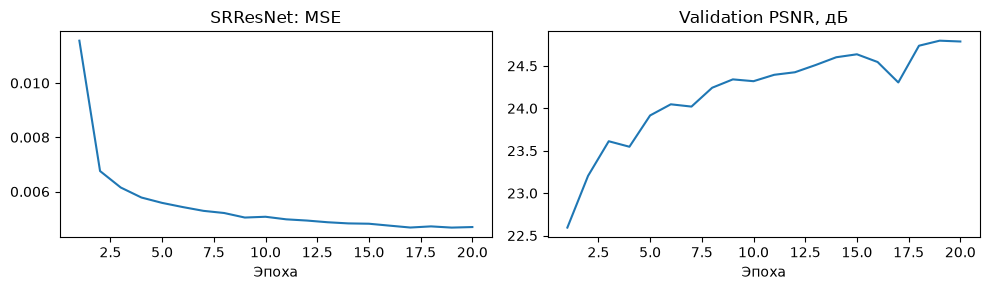

In [8]:
history_pre = json.loads((RESULTS_DIR / 'history_pre.json').read_text(encoding='utf-8'))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, key, title in zip(axes, ['loss', 'psnr'], ['SRResNet: MSE', 'Validation PSNR, дБ']):
    ax.plot(range(1, len(history_pre[key]) + 1), history_pre[key])
    ax.set_title(title)
    ax.set_xlabel('Эпоха')
plt.tight_layout()
plt.show()

## 6. Состязательное дообучение генератора
Начинаем с лучшего предобученного генератора. Обучаем D различать HR и SR,
затем G — минимизировать `VGG-loss + 0.001 × adversarial loss`.
На шаге G замораживаем параметры и BatchNorm дискриминатора.
Веса VGG19 уже закэшированы; на новой машине torchvision скачает их (~548 МБ).
Лучшие GAN-веса выбираются по validation PSNR; качество фактуры также смотрим визуально.

In [9]:
G = Generator().to(DEVICE)
G.load_state_dict(torch.load(RESULTS_DIR / 'best_pretrain.pt', map_location=DEVICE, weights_only=True)['generator'])
D = Discriminator().to(DEVICE)
vgg_loss = VGGContentLoss().to(DEVICE).eval()
bce = nn.BCEWithLogitsLoss()
optimizer_g = torch.optim.Adam(G.parameters(), lr=LEARNING_RATE)
optimizer_d = torch.optim.Adam(D.parameters(), lr=LEARNING_RATE)
scheduler_g = torch.optim.lr_scheduler.StepLR(optimizer_g, step_size=10, gamma=0.1)
scheduler_d = torch.optim.lr_scheduler.StepLR(optimizer_d, step_size=10, gamma=0.1)
history_gan = {'g_loss': [], 'd_loss': [], 'psnr': []}
best_psnr = -float('inf')

for epoch in range(GAN_EPOCHS):
    G.train()
    total_g, total_d = 0.0, 0.0
    for lr, hr in tqdm(train_loader, desc=f'SRGAN {epoch + 1}/{GAN_EPOCHS}'):
        lr, hr = lr.to(DEVICE), hr.to(DEVICE)
        optimizer_g.zero_grad(set_to_none=True)
        sr = G(lr)

        D.train()
        D.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)
        real_logits, fake_logits = D(hr), D(sr.detach())
        loss_d = (bce(real_logits, torch.ones_like(real_logits))
                  + bce(fake_logits, torch.zeros_like(fake_logits))) / 2
        loss_d.backward()
        optimizer_d.step()
        optimizer_d.zero_grad(set_to_none=True)

        D.eval()
        D.requires_grad_(False)
        logits = D(sr)
        loss_g = vgg_loss(sr, hr) + ADV_WEIGHT * bce(logits, torch.ones_like(logits))
        loss_g.backward()
        optimizer_g.step()
        total_g += loss_g.item() * len(hr)
        total_d += loss_d.item() * len(hr)

    G.eval()
    psnr, ssim = evaluate(G, val_loader)
    history_gan['g_loss'].append(total_g / len(train_dataset))
    history_gan['d_loss'].append(total_d / len(train_dataset))
    history_gan['psnr'].append(psnr)
    if psnr > best_psnr:
        best_psnr = psnr
        torch.save({'generator': G.state_dict()}, RESULTS_DIR / 'best_gan.pt')
    scheduler_g.step()
    scheduler_d.step()
    print(f'Эпоха {epoch + 1}: G={history_gan["g_loss"][-1]:.4f}, '
          f'D={history_gan["d_loss"][-1]:.4f}, PSNR={psnr:.2f}, SSIM={ssim:.3f}')

(RESULTS_DIR / 'history_gan.json').write_text(json.dumps(history_gan), encoding='utf-8')

SRGAN 1/20: 100%|██████████| 992/992 [03:52<00:00,  4.26it/s]


Эпоха 1: G=0.4221, D=0.1320, PSNR=22.21, SSIM=0.639


SRGAN 2/20: 100%|██████████| 992/992 [03:53<00:00,  4.25it/s]


Эпоха 2: G=0.4051, D=0.0208, PSNR=22.28, SSIM=0.639


SRGAN 3/20: 100%|██████████| 992/992 [03:57<00:00,  4.18it/s]


...

SRGAN 19/20: 100%|██████████| 992/992 [03:44<00:00,  4.41it/s]


Эпоха 19: G=0.3466, D=0.0000, PSNR=23.17, SSIM=0.616


SRGAN 20/20: 100%|██████████| 992/992 [03:46<00:00,  4.37it/s]


Эпоха 20: G=0.3451, D=0.0000, PSNR=23.13, SSIM=0.616


1297

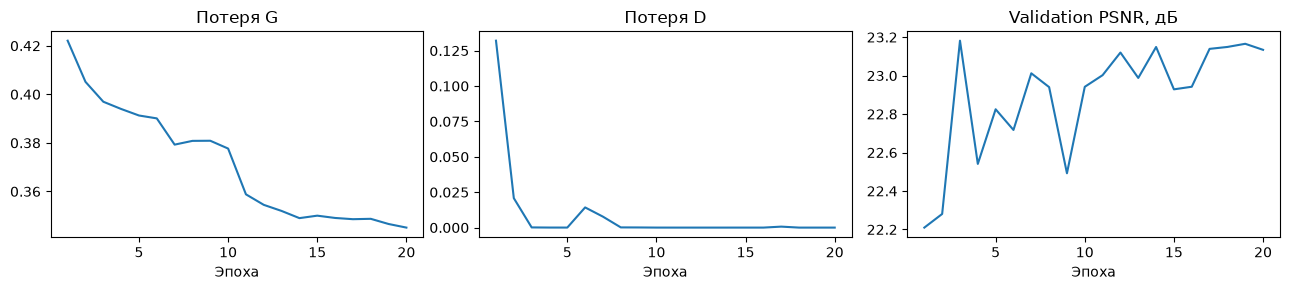

In [10]:
history_gan = json.loads((RESULTS_DIR / 'history_gan.json').read_text(encoding='utf-8'))
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, key, title in zip(axes, ['g_loss', 'd_loss', 'psnr'], ['Потеря G', 'Потеря D', 'Validation PSNR, дБ']):
    ax.plot(range(1, len(history_gan[key]) + 1), history_gan[key])
    ax.set_title(title)
    ax.set_xlabel('Эпоха')
plt.tight_layout()
plt.show()

## 7. Анализ результатов и визуальное сопоставление методов
Сравниваем bicubic, SRResNet и SRGAN на одной test-выборке. Все модели в режиме
`eval`, градиенты отключены. Численные результаты сохраняем в JSON, примеры — в PNG.

In [11]:
def load_generator(filename):
    model = Generator().to(DEVICE)
    weights = torch.load(RESULTS_DIR / filename, map_location=DEVICE, weights_only=True)
    model.load_state_dict(weights['generator'])
    return model.eval()


G_mse = load_generator('best_pretrain.pt')
G_gan = load_generator('best_gan.pt')
methods = {'Bicubic': lambda lr: bicubic_batch(lr, HR_SIZE).to(DEVICE),
           'SRResNet': G_mse, 'SRGAN': G_gan}
results = {name: evaluate(predict, test_loader) for name, predict in methods.items()}
print(f'{"Метод":<10} | {"PSNR, дБ":>8} | {"SSIM":>6}')
for name, (psnr, ssim) in results.items():
    print(f'{name:<10} | {psnr:8.2f} | {ssim:6.3f}')
(RESULTS_DIR / 'test_metrics.json').write_text(json.dumps(results, indent=2), encoding='utf-8')

Метод      | PSNR, дБ |   SSIM
Bicubic    |    23.43 |  0.637
SRResNet   |    24.68 |  0.689
SRGAN      |    23.06 |  0.631


202

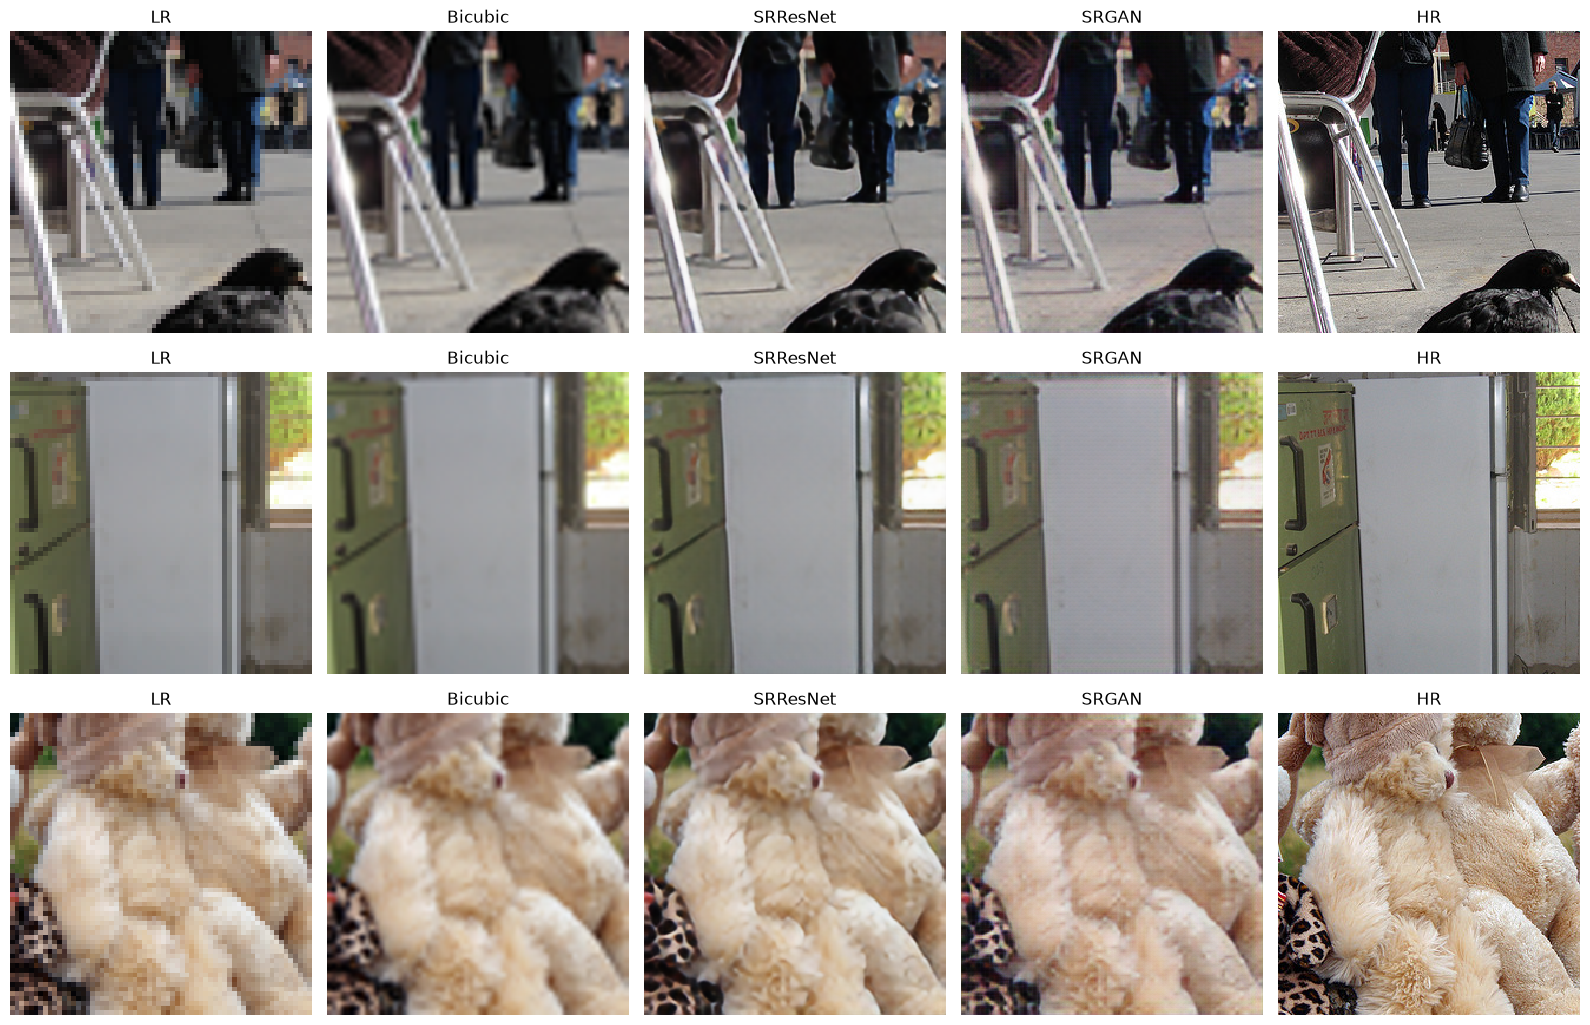

In [12]:
@torch.no_grad()
def show_examples(indices):
    fig, axes = plt.subplots(len(indices), 5, figsize=(16, 3.5 * len(indices)), squeeze=False)
    for row, index in enumerate(indices):
        lr, hr = test_dataset[index]
        batch = lr.unsqueeze(0).to(DEVICE)
        images = {'LR': lr, 'Bicubic': methods['Bicubic'](batch)[0].cpu(),
                  'SRResNet': G_mse(batch)[0].cpu(), 'SRGAN': G_gan(batch)[0].cpu(), 'HR': hr}
        for ax, (name, image) in zip(axes[row], images.items()):
            pixels = image.clamp(0, 1).permute(1, 2, 0).numpy()
            ax.imshow(pixels, interpolation='nearest')
            ax.set_title(name)
            ax.axis('off')
            Image.fromarray((pixels * 255).round().astype(np.uint8)).save(
                RESULTS_DIR / f'test_{index}_{name}.png')
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / 'comparison.png', dpi=150)
    plt.show()


show_examples([0, 1, 2])

## 8. Увеличение разрешения пользовательского снимка
Передайте путь к PNG, JPG или BMP. Модель увеличивает ширину и высоту в 4 раза.
Для большого входа может не хватить видеопамяти. Ниже — пример на маленьком
изображении; можно заменить путь своим файлом.

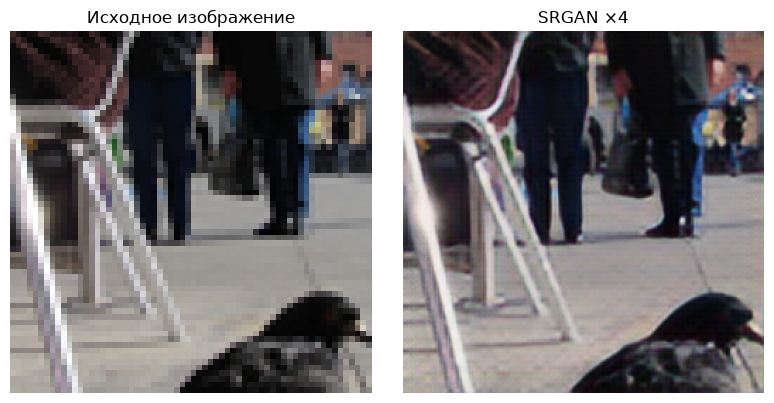

Сохранено: runs\srgan_coco_simple\my_image_x4.png


In [13]:
@torch.no_grad()
def upscale_file(input_path, output_path):
    with Image.open(input_path) as image:
        lr = ImageOps.exif_transpose(image).convert('RGB')
    tensor = transforms.ToTensor()(lr).unsqueeze(0).to(DEVICE)
    sr = G_gan(tensor)[0].clamp(0, 1).cpu().permute(1, 2, 0).numpy()
    Image.fromarray((sr * 255).round().astype(np.uint8)).save(output_path)
    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(lr)
    axes[1].imshow(sr)
    for ax, title in zip(axes, ['Исходное изображение', 'SRGAN ×4']):
        ax.set_title(title)
        ax.axis('off')
    plt.tight_layout()
    plt.show()
    print('Сохранено:', output_path)


upscale_file(RESULTS_DIR / 'test_0_LR.png', RESULTS_DIR / 'my_image_x4.png')